In [1]:
from google.colab import files
uploaded = files.upload ()

Saving HHS_Unaccompanied_Alien_Children_Program.csv to HHS_Unaccompanied_Alien_Children_Program.csv


In [2]:
import pandas as pd
import glob

# Locate and load dataset
file_path = glob.glob('/content/*.csv')[0]
df = pd.read_csv(file_path)

# Basic dataset information
print("DATASET DIMENSIONS:", df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nFIRST 5 RECORDS:")
display(df.head())

print("\nLAST 5 RECORDS:")
display(df.tail())

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY:")
display(df.describe(include='all'))

DATASET DIMENSIONS: (1170, 6)

COLUMN NAMES:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']

DATA TYPES:
Date                                                object
Children apprehended and placed in CBP custody*    float64
Children in CBP custody                            float64
Children transferred out of CBP custody            float64
Children in HHS Care                                object
Children discharged from HHS Care                  float64
dtype: object

FIRST 5 RECORDS:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0



LAST 5 RECORDS:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
1165,NaN,NaN,NaN,NaN,NaN,NaN
1166,NaN,NaN,NaN,NaN,NaN,NaN
1167,NaN,NaN,NaN,NaN,NaN,NaN
1168,NaN,NaN,NaN,NaN,NaN,NaN
1169,NaN,NaN,NaN,NaN,NaN,NaN



MISSING VALUES:
Date                                               450
Children apprehended and placed in CBP custody*    450
Children in CBP custody                            450
Children transferred out of CBP custody            450
Children in HHS Care                               450
Children discharged from HHS Care                  450
dtype: int64

DUPLICATE ROWS:
449

STATISTICAL SUMMARY:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720,720.000000,720.000000,720.000000,720,720.000000
unique,720,NaN,NaN,NaN,642,NaN
top,"December 21, 2025",NaN,NaN,NaN,"5,963",NaN
freq,1,NaN,NaN,NaN,3,NaN
mean,NaN,93.523611,171.494444,128.668056,NaN,173.406944
std,NaN,72.646625,126.354965,97.322012,NaN,125.702841
min,NaN,0.000000,7.000000,0.000000,NaN,0.000000
25%,NaN,12.000000,36.000000,14.000000,NaN,19.750000
50%,NaN,99.000000,193.000000,157.000000,NaN,181.000000
75%,NaN,147.250000,263.250000,199.250000,NaN,267.000000


In [3]:
print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nFIRST AND LAST DATE")
print(df['Date'].iloc[0], "to", df['Date'].iloc[-1])

print("\nSTATISTICAL SUMMARY")
display(df.describe())

DATA TYPES
Date                                                object
Children apprehended and placed in CBP custody*    float64
Children in CBP custody                            float64
Children transferred out of CBP custody            float64
Children in HHS Care                                object
Children discharged from HHS Care                  float64
dtype: object

MISSING VALUES
Date                                               450
Children apprehended and placed in CBP custody*    450
Children in CBP custody                            450
Children transferred out of CBP custody            450
Children in HHS Care                               450
Children discharged from HHS Care                  450
dtype: int64

DUPLICATE ROWS
449

FIRST AND LAST DATE
December 21, 2025 to nan

STATISTICAL SUMMARY


,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children discharged from HHS Care
count,720.000000,720.000000,720.000000,720.000000
mean,93.523611,171.494444,128.668056,173.406944
std,72.646625,126.354965,97.322012,125.702841
min,0.000000,7.000000,0.000000,0.000000
25%,12.000000,36.000000,14.000000,19.750000
50%,99.000000,193.000000,157.000000,181.000000
75%,147.250000,263.250000,199.250000,267.000000
max,333.000000,531.000000,440.000000,505.000000


In [4]:
# Create a separate working copy
df_clean = df.copy()

# Remove completely empty rows
df_clean = df_clean.dropna(how='all')

# Convert Date into datetime format
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    errors='coerce'
)

# Convert HHS Care into numeric format
df_clean['Children in HHS Care'] = pd.to_numeric(
    df_clean['Children in HHS Care'],
    errors='coerce'
)

# Check the cleaned dataset
print("NEW DIMENSIONS:", df_clean.shape)

print("\nMISSING VALUES:")
print(df_clean.isnull().sum())

print("\nDUPLICATES:")
print(df_clean.duplicated().sum())

print("\nDATE RANGE:")
print(df_clean['Date'].min(), "to", df_clean['Date'].max())

print("\nDATA TYPES:")
print(df_clean.dtypes)

print("\nFIRST 5 RECORDS:")
display(df_clean.head())

NEW DIMENSIONS: (720, 6)

MISSING VALUES:
Date                                                 0
Children apprehended and placed in CBP custody*      0
Children in CBP custody                              0
Children transferred out of CBP custody              0
Children in HHS Care                               720
Children discharged from HHS Care                    0
dtype: int64

DUPLICATES:
0

DATE RANGE:
2023-01-12 00:00:00 to 2025-12-21 00:00:00

DATA TYPES:
Date                                               datetime64[ns]
Children apprehended and placed in CBP custody*           float64
Children in CBP custody                                   float64
Children transferred out of CBP custody                   float64
Children in HHS Care                                      float64
Children discharged from HHS Care                         float64
dtype: object

FIRST 5 RECORDS:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2025-12-21,6.0,18.0,11.0,NaN,14.0
1,2025-12-18,11.0,50.0,6.0,NaN,16.0
2,2025-12-17,7.0,31.0,11.0,NaN,10.0
3,2025-12-16,8.0,54.0,15.0,NaN,9.0
4,2025-12-15,11.0,42.0,9.0,NaN,7.0


In [5]:
# Start again from original dataset
df_clean = df.dropna(how='all').copy()

# Convert all numeric columns, removing commas
numeric_cols = df_clean.columns.drop('Date')

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.replace(',', ''),
        errors='coerce'
    )

# Sort dates chronologically
df_clean['Date'] = pd.to_datetime(df_clean['Date'])
df_clean = df_clean.sort_values('Date').reset_index(drop=True)

# Audit
print("DIMENSIONS:", df_clean.shape)

print("\nMISSING VALUES:")
print(df_clean.isnull().sum())

print("\nDUPLICATE DATES:", df_clean['Date'].duplicated().sum())

print("\nDATE GAPS:")
print(df_clean['Date'].diff().value_counts().head(10))

print("\nDATE RANGE:")
print(df_clean['Date'].min(), "to", df_clean['Date'].max())

print("\nDATA TYPES:")
print(df_clean.dtypes)

display(df_clean.head())

DIMENSIONS: (720, 6)

MISSING VALUES:
Date                                               0
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

DUPLICATE DATES: 0

DATE GAPS:
Date
1 days     558
3 days     122
4 days      23
2 days      10
5 days       3
10 days      1
6 days       1
7 days       1
Name: count, dtype: int64

DATE RANGE:
2023-01-12 00:00:00 to 2025-12-21 00:00:00

DATA TYPES:
Date                                               datetime64[ns]
Children apprehended and placed in CBP custody*           float64
Children in CBP custody                                   float64
Children transferred out of CBP custody                   float64
Children in HHS Care                                        int64
Children discharged from HHS Care                

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33.0,53.0,34.0,6566,436.0
1,2023-01-22,32.0,49.0,39.0,7122,227.0
2,2023-01-23,32.0,50.0,39.0,7280,181.0
3,2023-01-24,47.0,42.0,47.0,7433,175.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0


In [6]:
# Calculate missing calendar dates
all_dates = pd.date_range(
    start=df_clean['Date'].min(),
    end=df_clean['Date'].max(),
    freq='D'
)

missing_dates = all_dates.difference(df_clean['Date'])

print("EXPECTED DAILY RECORDS:", len(all_dates))
print("ACTUAL RECORDS:", len(df_clean))
print("MISSING CALENDAR DAYS:", len(missing_dates))

print("\nFIRST 20 MISSING DATES:")
print(missing_dates[:20])

# Check monthly data coverage
monthly = df_clean.set_index('Date').resample('ME').size()

print("\nMONTHLY RECORD COUNT:")
display(monthly)

EXPECTED DAILY RECORDS: 1075
ACTUAL RECORDS: 720
MISSING CALENDAR DAYS: 355

FIRST 20 MISSING DATES:
DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26', '2023-01-27', '2023-01-28',
               '2023-02-03', '2023-02-04', '2023-02-10', '2023-02-11',
               '2023-02-17', '2023-02-18', '2023-02-19', '2023-02-24'],
              dtype='datetime64[ns]', freq=None)

MONTHLY RECORD COUNT:


,0
Date,
2023-01-31,8
2023-02-28,19
2023-03-31,19
2023-04-30,21
2023-05-31,22
2023-06-30,20
2023-07-31,21
2023-08-31,20
2023-09-30,19


In [7]:
# Identify weekdays in observed data
df_clean['Weekday'] = df_clean['Date'].dt.day_name()

print("OBSERVED RECORDS BY WEEKDAY:")
print(df_clean['Weekday'].value_counts())

# Identify weekdays in the complete calendar
calendar = pd.DataFrame({
    'Date': pd.date_range(
        df_clean['Date'].min(),
        df_clean['Date'].max(),
        freq='D'
    )
})

calendar['Weekday'] = calendar['Date'].dt.day_name()

print("\nTOTAL CALENDAR DAYS BY WEEKDAY:")
print(calendar['Weekday'].value_counts())

# Compare reporting coverage
print("\nREPORTING COVERAGE:")
print(
    df_clean['Weekday'].value_counts()
    / calendar['Weekday'].value_counts() * 100
)

OBSERVED RECORDS BY WEEKDAY:
Weekday
Tuesday      149
Thursday     147
Wednesday    147
Monday       145
Sunday       130
Friday         2
Name: count, dtype: int64

TOTAL CALENDAR DAYS BY WEEKDAY:
Weekday
Thursday     154
Friday       154
Saturday     154
Sunday       154
Monday       153
Tuesday      153
Wednesday    153
Name: count, dtype: int64

REPORTING COVERAGE:
Weekday
Friday        1.298701
Monday       94.771242
Saturday           NaN
Sunday       84.415584
Thursday     95.454545
Tuesday      97.385621
Wednesday    96.078431
Name: count, dtype: float64


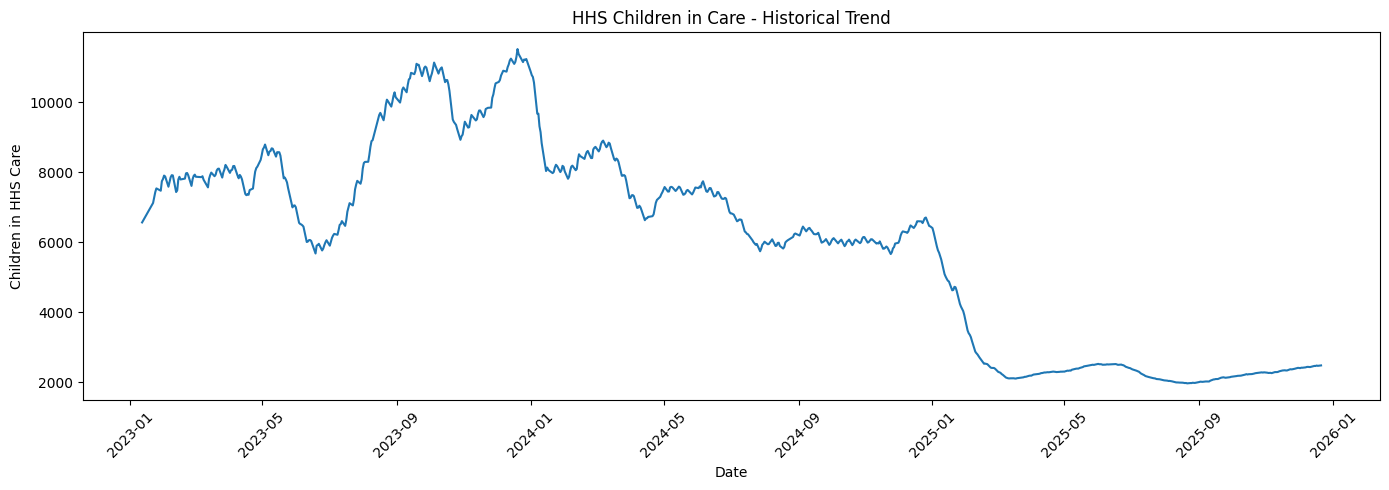

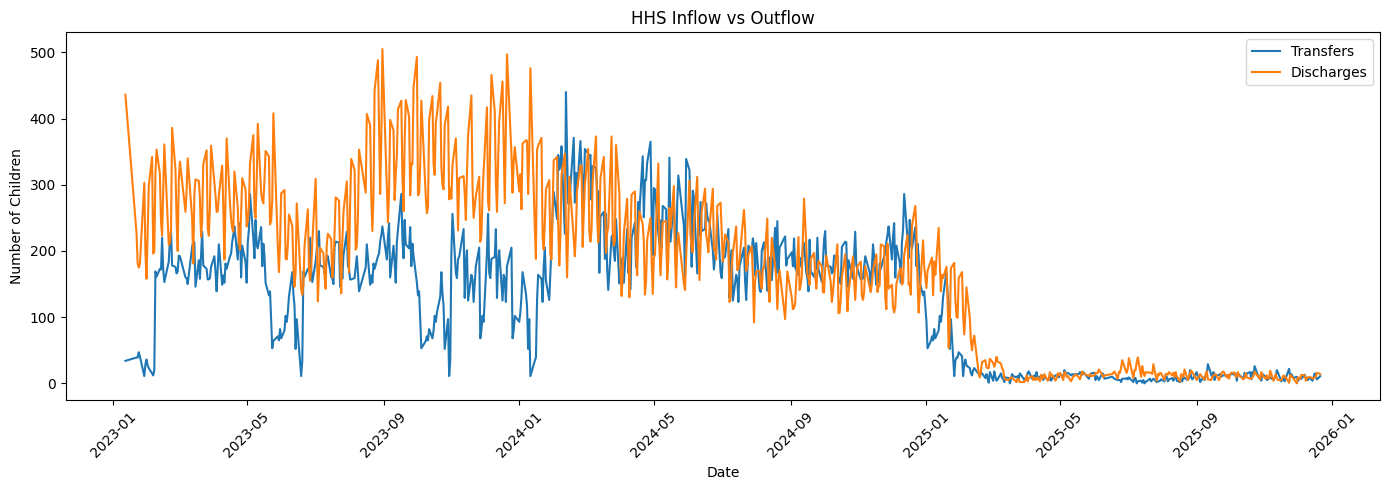

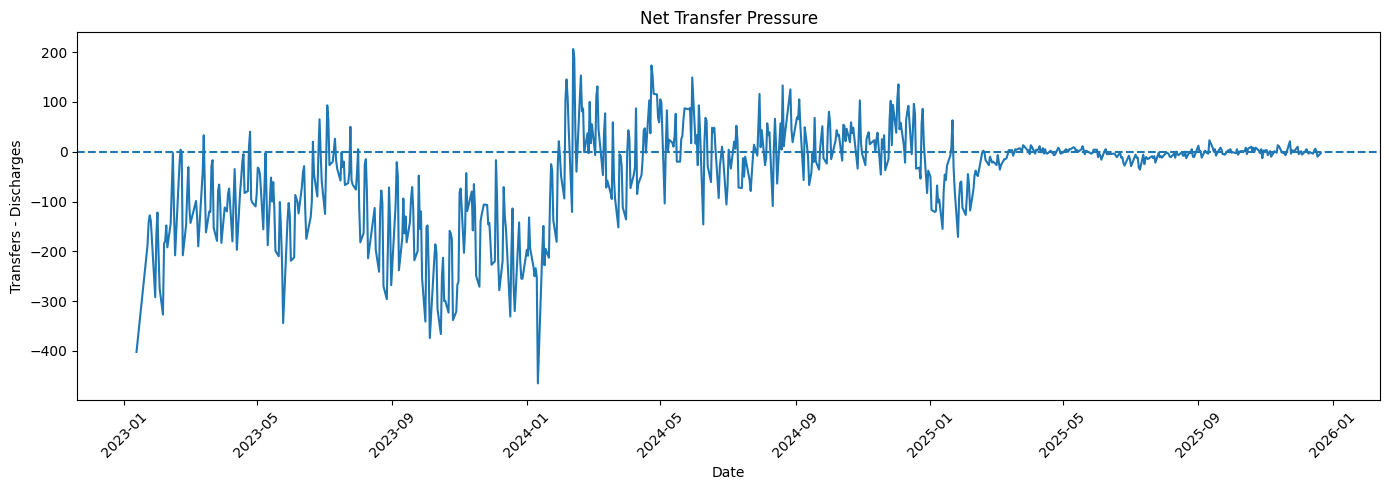

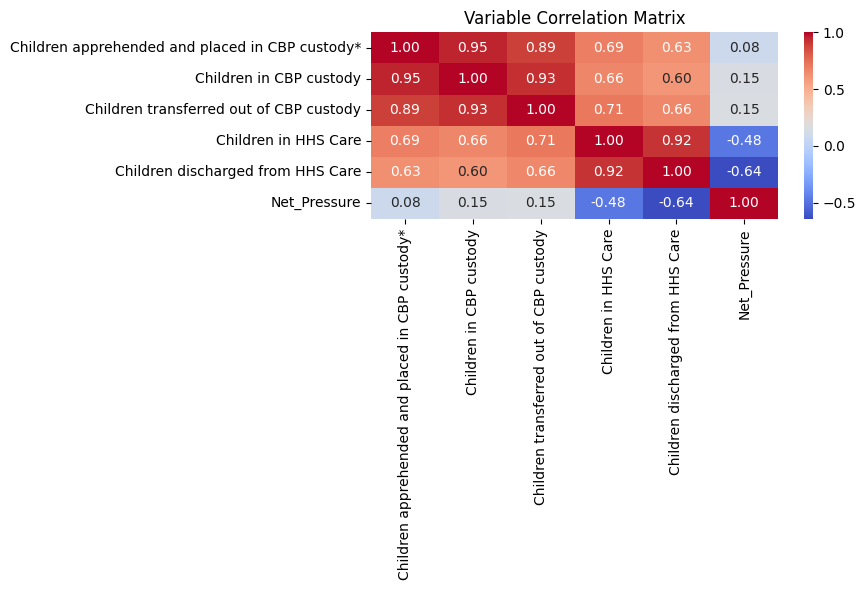

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. HHS Care Load over time
plt.figure(figsize=(14,5))
plt.plot(df_clean['Date'], df_clean['Children in HHS Care'])
plt.title('HHS Children in Care - Historical Trend')
plt.xlabel('Date')
plt.ylabel('Children in HHS Care')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Transfers vs Discharges
plt.figure(figsize=(14,5))
plt.plot(df_clean['Date'],
         df_clean['Children transferred out of CBP custody'],
         label='Transfers')
plt.plot(df_clean['Date'],
         df_clean['Children discharged from HHS Care'],
         label='Discharges')
plt.title('HHS Inflow vs Outflow')
plt.xlabel('Date')
plt.ylabel('Number of Children')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Net operational pressure
df_clean['Net_Pressure'] = (
    df_clean['Children transferred out of CBP custody']
    - df_clean['Children discharged from HHS Care']
)

plt.figure(figsize=(14,5))
plt.plot(df_clean['Date'], df_clean['Net_Pressure'])
plt.axhline(0, linestyle='--')
plt.title('Net Transfer Pressure')
plt.xlabel('Date')
plt.ylabel('Transfers - Discharges')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 4. Correlation analysis
correlation = df_clean.select_dtypes(include='number').corr()

plt.figure(figsize=(9,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Variable Correlation Matrix')
plt.tight_layout()
plt.show()

In [9]:
print("HHS CARE STATISTICS")
print(df_clean['Children in HHS Care'].describe())

print("\nNET PRESSURE STATISTICS")
print(df_clean['Net_Pressure'].describe())

print("\nCORRELATION WITH HHS CARE")
print(correlation['Children in HHS Care'].sort_values(ascending=False))

HHS CARE STATISTICS
count      720.000000
mean      6061.275000
std       2833.070109
min       1972.000000
25%       2467.750000
50%       6406.500000
75%       8010.250000
max      11516.000000
Name: Children in HHS Care, dtype: float64

NET PRESSURE STATISTICS
count    720.000000
mean     -44.738889
std       95.863856
min     -465.000000
25%      -94.250000
50%      -11.500000
75%        5.250000
max      206.000000
Name: Net_Pressure, dtype: float64

CORRELATION WITH HHS CARE
Children in HHS Care                               1.000000
Children discharged from HHS Care                  0.920881
Children transferred out of CBP custody            0.713899
Children apprehended and placed in CBP custody*    0.691312
Children in CBP custody                            0.663662
Net_Pressure                                      -0.482760
Name: Children in HHS Care, dtype: float64


In [10]:
# Split dataset into two periods
before = df_clean[df_clean['Date'] < '2025-01-01']
after = df_clean[df_clean['Date'] >= '2025-01-01']

metrics = [
    'Children in HHS Care',
    'Children transferred out of CBP custody',
    'Children discharged from HHS Care',
    'Net_Pressure'
]

print("BEFORE JANUARY 2025")
display(before[metrics].describe().round(2))

print("\nAFTER JANUARY 2025")
display(after[metrics].describe().round(2))


# Inspect observations around the transition
transition = df_clean[
    (df_clean['Date'] >= '2024-12-01') &
    (df_clean['Date'] <= '2025-03-31')
]

display(transition[
    ['Date'] + metrics
].to_string(index=False))

BEFORE JANUARY 2025


,Children in HHS Care,Children transferred out of CBP custody,Children discharged from HHS Care,Net_Pressure
count,481.00,481.00,481.00,481.00
mean,7809.52,184.36,245.18,-60.83
std,1563.65,67.42,84.28,111.94
min,5664.00,11.00,92.00,-465.00
25%,6402.00,156.00,177.00,-132.00
50%,7583.00,181.00,231.00,-44.00
75%,8650.00,218.00,299.00,23.00
max,11516.00,440.00,505.00,206.00



AFTER JANUARY 2025


,Children in HHS Care,Children transferred out of CBP custody,Children discharged from HHS Care,Net_Pressure
count,239.00,239.00,239.00,239.00
mean,2542.84,16.59,28.95,-12.36
std,841.45,23.74,45.22,30.25
min,1972.00,0.00,0.00,-171.00
25%,2145.00,6.00,8.00,-12.00
50%,2294.00,10.00,13.00,-3.00
75%,2464.50,15.00,19.00,2.00
max,6405.00,168.00,235.00,63.00


'      Date  Children in HHS Care  Children transferred out of CBP custody  Children discharged from HHS Care  Net_Pressure\n2024-12-01                  5986                                    187.0                              149.0          38.0\n2024-12-02                  6061                                    222.0                              115.0         107.0\n2024-12-03                  6192                                    242.0                              107.0         135.0\n2024-12-04                  6269                                    160.0                              115.0          45.0\n2024-12-05                  6310                                    208.0                              150.0          58.0\n2024-12-08                  6286                                    183.0                              172.0          11.0\n2024-12-09                  6268                                    152.0                              174.0         -22.0\n2024-12

In [11]:
transition = df_clean[
    (df_clean['Date'] >= '2024-12-15') &
    (df_clean['Date'] <= '2025-02-28')
].copy()

transition['HHS_Change'] = (
    transition['Children in HHS Care'].diff()
)

display(transition[
    ['Date',
     'Children in HHS Care',
     'HHS_Change',
     'Children transferred out of CBP custody',
     'Children discharged from HHS Care']
].to_string(index=False))

'      Date  Children in HHS Care  HHS_Change  Children transferred out of CBP custody  Children discharged from HHS Care\n2024-12-15                  6408         NaN                                    219.0                              224.0\n2024-12-16                  6454        46.0                                    189.0                              149.0\n2024-12-17                  6506        52.0                                    247.0                              151.0\n2024-12-18                  6598        92.0                                    210.0                              134.0\n2024-12-19                  6600         2.0                                    204.0                              238.0\n2024-12-22                  6595        -5.0                                    236.0                              268.0\n2024-12-23                  6548       -47.0                                    177.0                              231.0\n2024-12-24             

In [12]:
# Calculate time gap and change between observations
audit = df_clean[['Date', 'Children in HHS Care']].copy()

audit['Previous_Date'] = audit['Date'].shift(1)

audit['Days_Gap'] = (
    audit['Date'] - audit['Previous_Date']
).dt.days

audit['HHS_Change'] = (
    audit['Children in HHS Care'].diff()
)

# Find the 10 biggest declines
biggest_drops = audit.nsmallest(10, 'HHS_Change')

display(biggest_drops)

# Monthly average HHS care
monthly_hhs = (
    df_clean.set_index('Date')['Children in HHS Care']
    .resample('ME').mean()
)

display(monthly_hhs.round(0))

,Date,Children in HHS Care,Previous_Date,Days_Gap,HHS_Change
234,2024-01-07,9670,2024-01-04,3.0,-888.0
183,2023-10-22,9506,2023-10-19,3.0,-813.0
239,2024-01-15,8033,2024-01-11,4.0,-796.0
81,2023-05-21,7826,2023-05-18,3.0,-648.0
86,2023-05-29,6996,2023-05-25,4.0,-550.0
292,2024-03-31,7257,2024-03-28,3.0,-505.0
15,2023-02-12,7434,2023-02-09,3.0,-474.0
90,2023-06-04,6555,2023-06-01,3.0,-447.0
503,2025-02-02,3483,2025-01-30,3.0,-440.0
95,2023-06-11,6007,2023-06-08,3.0,-439.0


,Children in HHS Care
Date,
2023-01-31,7370.0
2023-02-28,7796.0
2023-03-31,7945.0
2023-04-30,7843.0
2023-05-31,8187.0
2023-06-30,6136.0
2023-07-31,6828.0
2023-08-31,9348.0
2023-09-30,10701.0


In [13]:
# Create modelling dataset
df_model = df_clean.sort_values('Date').copy()

target = 'Children in HHS Care'

# Lag features
for lag in [1, 7, 14]:
    df_model[f'lag_{lag}'] = df_model[target].shift(lag)

# Rolling averages (shift first to prevent data leakage)
df_model['rolling_mean_7'] = (
    df_model[target].shift(1).rolling(7).mean()
)

df_model['rolling_mean_14'] = (
    df_model[target].shift(1).rolling(14).mean()
)

# Calendar features
df_model['Month'] = df_model['Date'].dt.month
df_model['Weekday'] = df_model['Date'].dt.dayofweek

# Predict next observed HHS care value
df_model['Target'] = df_model[target].shift(-1)

# Remove rows without sufficient history or target
df_model = df_model.dropna().reset_index(drop=True)

print("MODELLING DATA DIMENSIONS:", df_model.shape)

print("\nFEATURE COLUMNS:")
print(df_model.columns.tolist())

print("\nFIRST 5 ROWS:")
display(df_model.head())

print("\nLAST 5 ROWS:")
display(df_model.tail())

MODELLING DATA DIMENSIONS: (705, 15)

FEATURE COLUMNS:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care', 'Weekday', 'Net_Pressure', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14', 'Month', 'Target']

FIRST 5 ROWS:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Weekday,Net_Pressure,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,Month,Target
0,2023-02-09,124.0,234.0,161.0,7908,353.0,3,-192.0,7915.0,7803.0,6566.0,7808.714286,7558.214286,2,7434.0
1,2023-02-12,92.0,203.0,173.0,7434,317.0,6,-144.0,7908.0,7903.0,7122.0,7823.714286,7654.071429,2,7483.0
2,2023-02-13,186.0,259.0,172.0,7483,244.0,0,-72.0,7434.0,7879.0,7280.0,7756.714286,7676.357143,2,7794.0
3,2023-02-14,154.0,225.0,220.0,7794,223.0,1,-3.0,7483.0,7586.0,7433.0,7700.142857,7690.857143,2,7869.0
4,2023-02-15,91.0,199.0,172.0,7869,290.0,2,-118.0,7794.0,7720.0,7538.0,7729.857143,7716.642857,2,7793.0



LAST 5 ROWS:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Weekday,Net_Pressure,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14,Month,Target
700,2025-12-14,8.0,35.0,4.0,2462,8.0,6,-4.0,2437.0,2419.0,2375.0,2432.142857,2411.928571,12,2470.0
701,2025-12-15,11.0,42.0,9.0,2470,7.0,0,2.0,2462.0,2418.0,2371.0,2438.285714,2418.142857,12,2468.0
702,2025-12-16,8.0,54.0,15.0,2468,9.0,1,6.0,2470.0,2429.0,2375.0,2445.714286,2425.214286,12,2481.0
703,2025-12-17,7.0,31.0,11.0,2481,10.0,2,1.0,2468.0,2440.0,2389.0,2451.285714,2431.857143,12,2472.0
704,2025-12-18,11.0,50.0,6.0,2472,16.0,3,-10.0,2481.0,2443.0,2415.0,2457.142857,2438.428571,12,2484.0


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 80:20 chronological split
split = int(len(df_model) * 0.8)

train = df_model.iloc[:split].copy()
test = df_model.iloc[split:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

# Actual values
y_true = test['Target']

# Model 1: Naive persistence
naive_predictions = test['Children in HHS Care']

# Model 2: Moving average
ma_predictions = test['rolling_mean_7']

# Evaluation function
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    return {
        'Model': name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE (%)': round(mape, 2)
    }

results = [
    evaluate_model('Naive Persistence', y_true, naive_predictions),
    evaluate_model('Moving Average', y_true, ma_predictions)
]

results_df = pd.DataFrame(results)

display(results_df)

Training observations: 564
Testing observations: 141


,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,10.30,14.08,0.46
1,Moving Average,41.03,50.11,1.83


In [15]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Select input features
features = [
    'Children in HHS Care',
    'Children transferred out of CBP custody',
    'Children discharged from HHS Care',
    'Net_Pressure',
    'lag_1',
    'lag_7',
    'lag_14',
    'rolling_mean_7',
    'rolling_mean_14',
    'Month',
    'Weekday'
]

X_train = train[features]
X_test = test[features]

y_train = train['Target']
y_test = test['Target']

# Random Forest
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

rf.fit(X_train, y_train)
rf_predictions = rf.predict(X_test)

# Gradient Boosting
gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)
gb_predictions = gb.predict(X_test)

# Compare all four models
results = [
    evaluate_model('Naive Persistence', y_test, test['Children in HHS Care']),
    evaluate_model('Moving Average', y_test, test['rolling_mean_7']),
    evaluate_model('Random Forest', y_test, rf_predictions),
    evaluate_model('Gradient Boosting', y_test, gb_predictions)
]

final_results = pd.DataFrame(results).sort_values('MAE')

display(final_results)

,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,10.30,14.08,0.46
1,Moving Average,41.03,50.11,1.83
2,Random Forest,61.70,83.24,2.86
3,Gradient Boosting,75.67,97.62,3.56


In [16]:
# Walk-forward validation of naive model

from sklearn.metrics import mean_absolute_error
import numpy as np

series = df_clean['Children in HHS Care'].values

horizons = [1, 7, 14]
validation_results = []

for horizon in horizons:

    errors = []

    for i in range(len(series) - horizon - 100, len(series) - horizon):

        actual = series[i + horizon]
        predicted = series[i]

        errors.append(abs(actual - predicted))

    validation_results.append({
        'Horizon (observations)': horizon,
        'MAE': round(np.mean(errors), 2)
    })

display(pd.DataFrame(validation_results))

,Horizon (observations),MAE
0,1,8.38
1,7,43.76
2,14,89.50


In [17]:
# Forecast horizon
horizon = 14

# Latest observations
last_hhs = df_clean['Children in HHS Care'].iloc[-1]
last_discharge = df_clean['Children discharged from HHS Care'].iloc[-1]

# Generate baseline forecasts
forecast = pd.DataFrame({
    'Forecast_Step': range(1, horizon + 1),
    'Predicted_HHS_Care': [last_hhs] * horizon,
    'Predicted_Discharge_Demand': [last_discharge] * horizon
})

display(forecast)

print("LATEST HHS CARE:", last_hhs)
print("LATEST DISCHARGES:", last_discharge)

,Forecast_Step,Predicted_HHS_Care,Predicted_Discharge_Demand
0,1,2484,14.0
1,2,2484,14.0
2,3,2484,14.0
3,4,2484,14.0
4,5,2484,14.0
5,6,2484,14.0
6,7,2484,14.0
7,8,2484,14.0
8,9,2484,14.0
9,10,2484,14.0


LATEST HHS CARE: 2484
LATEST DISCHARGES: 14.0


In [18]:
import os

# Create project output folder
os.makedirs('/content/project_outputs', exist_ok=True)

# 1. Cleaned dataset
df_clean.to_csv(
    '/content/project_outputs/cleaned_dataset.csv',
    index=False
)

# 2. Model comparison
final_results.to_csv(
    '/content/project_outputs/model_comparison.csv',
    index=False
)

# 3. Forecast output
forecast.to_csv(
    '/content/project_outputs/future_forecast.csv',
    index=False
)

# 4. Validation results
validation_df = pd.DataFrame(validation_results)

validation_df.to_csv(
    '/content/project_outputs/walk_forward_validation.csv',
    index=False
)

print("PROJECT FILES CREATED:")
print(os.listdir('/content/project_outputs'))

PROJECT FILES CREATED:
['walk_forward_validation.csv', 'cleaned_dataset.csv', 'model_comparison.csv', 'future_forecast.csv']


In [19]:
from google.colab import files
import os

for filename in os.listdir('/content/project_outputs'):
    files.download('/content/project_outputs/' + filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>